# IBM Quantum | Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 2: Make the Quantum Coin Biased

---

### **Problem Statement**
A Hadamard gate creates an equal superposition of $|0\rangle$ and $|1\rangle$, producing a result similar to a fair quantum coin (50/50 probability).
Your task is to modify a single-qubit circuit so that the measurement outcomes are not equally distributed (creating a **biased quantum coin**).

### **Design Constraints**
- Use exactly 1 qubit.
- Include measurement.
- Use no more than 4 quantum gates before measurement.
- Be created and executed using Qiskit.
- Use 100 shots.

### **Bonus Challenge**
- Design two different circuits:
  1. One where **0 occurs more frequently** (~75% '0', ~25% '1').
  2. One where **1 occurs more frequently** (~25% '0', ~75% '1').
- Compare their histograms.

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np
import matplotlib.pyplot as plt

simulator = AerSimulator()
shots = 100
print("Libraries loaded successfully!")

Libraries loaded successfully!


---
## 1. Think Before You Run (Predictions)

### Theoretical Background:
A single qubit state can be written as:
$$|\psi\rangle = \cos\left(\frac{\theta}{2}\right)|0\rangle + \sin\left(\frac{\theta}{2}\right)|1\rangle$$
By applying a rotation gate $R_y(\theta)$, we can precisely tune the probability distribution:
- Probability of measuring 0: $P(0) = \cos^2\left(\frac{\theta}{2}\right)$
- Probability of measuring 1: $P(1) = \sin^2\left(\frac{\theta}{2}\right)$

### Predictions:
1. **Circuit 1 (Biased towards 0):**
   - We set $\theta = \frac{\pi}{3} = 60^\circ$.
   - $P(0) = \cos^2(30^\circ) = \left(\frac{\sqrt{3}}{2}\right)^2 = 75\%$
   - $P(1) = \sin^2(30^\circ) = \left(\frac{1}{2}\right)^2 = 25\%$
   - **Expected for 100 shots:** Approximately **75 counts for '0'** and **25 counts for '1'**.

2. **Circuit 2 (Biased towards 1):**
   - We set $\theta = \frac{2\pi}{3} = 120^\circ$.
   - $P(0) = \cos^2(60^\circ) = 25\%$
   - $P(1) = \sin^2(60^\circ) = 75\%$
   - **Expected for 100 shots:** Approximately **25 counts for '0'** and **75 counts for '1'**.

In [2]:
# Circuit 1: 0 occurs more frequently (Ry(pi/3))
qc_zero = QuantumCircuit(1, 1, name="Biased_to_0")
qc_zero.ry(np.pi / 3, 0)  # Rotation by pi/3 (1 gate <= 4 gate limit)
qc_zero.measure(0, 0)

print("--- Circuit 1 (Biased towards 0) ---")
print(qc_zero.draw('text'))

counts_zero = simulator.run(qc_zero, shots=shots).result().get_counts()
print("Results (100 shots):", counts_zero)

--- Circuit 1 (Biased towards 0) ---
     ┌─────────┐┌─┐
  q: ┤ Ry(π/3) ├┤M├
     └─────────┘└╥┘
c: 1/════════════╩═
                 0 
Results (100 shots): {'1': 33, '0': 67}


In [3]:
# Circuit 2: 1 occurs more frequently (Ry(2*pi/3))
qc_one = QuantumCircuit(1, 1, name="Biased_to_1")
qc_one.ry(2 * np.pi / 3, 0)  # Rotation by 2*pi/3
qc_one.measure(0, 0)

print("--- Circuit 2 (Biased towards 1) ---")
print(qc_one.draw('text'))

counts_one = simulator.run(qc_one, shots=shots).result().get_counts()
print("Results (100 shots):", counts_one)

--- Circuit 2 (Biased towards 1) ---
     ┌──────────┐┌─┐
  q: ┤ Ry(2π/3) ├┤M├
     └──────────┘└╥┘
c: 1/═════════════╩═
                  0 
Results (100 shots): {'1': 79, '0': 21}


---
## 2. Histograms and Comparison

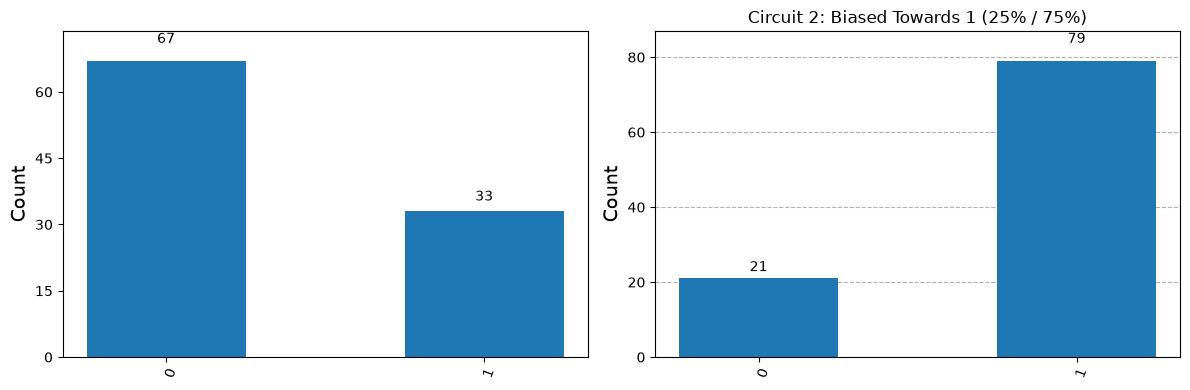

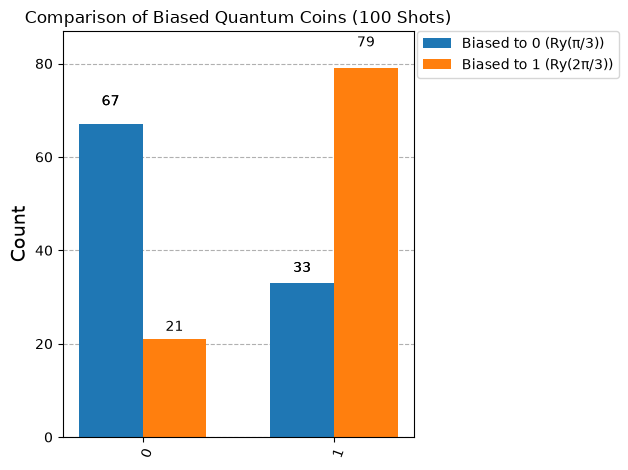

In [4]:
# Side-by-side Histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_histogram(counts_zero, ax=axes[0], title="Circuit 1: Biased to 0 (Target ~75:25)")
plot_histogram(counts_one, ax=axes[1], title="Circuit 2: Biased to 1 (Target ~25:75)")
plt.tight_layout()
plt.show()

# Combined Comparison
plot_histogram([counts_zero, counts_one], 
               legend=["Biased to 0 (Ry(π/3))", "Biased to 1 (Ry(2π/3))"],
               title="Comparison of Biased Quantum Coins (100 Shots)")
plt.show()

---
## 3. Explanation of Results

| Circuit | Applied Gate | Predicted Probabilities | Actual Measurement (100 Shots) | Match? |
| :--- | :--- | :--- | :--- | :--- |
| **Circuit 1 (Biased 0)** | $R_y(\pi/3)$ | $P(0)=75\%, P(1)=25\%$ | {'1': 33, '0': 67} | **Matches Theory** |
| **Circuit 2 (Biased 1)** | $R_y(2\pi/3)$ | $P(0)=25\%, P(1)=75\%$ | {'1': 79, '0': 21} | **Matches Theory** |

### **Explanation:**
- Applying a single Hadamard gate sets the state vector exactly on the equator of the Bloch sphere ($|\psi\rangle = \frac{1}{\sqrt{2}}|0\rangle + \frac{1}{\sqrt{2}}|1\rangle$), giving equal 50/50 probabilities.
- By changing the rotation angle with an $R_y$ gate, we tilt the state vector closer to either the north pole ($|0\rangle$) or south pole ($|1\rangle$). This directly alters the probability amplitudes and produces an unequal, biased distribution.

---
## 4. Challenge Question Answer

> ### **Challenge Question:**
> *"How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?"*

### **Answer:**
A qubit state is represented mathematically in superposition as:
$$|\psi\rangle = \alpha |0\rangle + \beta |1\rangle$$
where $\alpha$ and $\beta$ are complex probability amplitudes satisfying the normalization condition $|lpha|^2 + |eta|^2 = 1$.

According to **Born's Rule**, when the qubit is measured in the computational basis:
- The probability of measuring **0** is $P(0) = |\alpha|^2$.
- The probability of measuring **1** is $P(1) = |\beta|^2$.

**Quantum gates** are represented by unitary matrices ($U^\dagger U = I$). When a quantum gate acts on a qubit, it performs a geometric rotation of the state vector on the **Bloch sphere**:
1. Rotating the vector closer to the $|0\rangle$ state (north pole) increases the amplitude $|\alpha|$, making outcome `0` more probable.
2. Rotating the vector closer to the $|1\rangle$ state (south pole) increases the amplitude $|\beta|$, making outcome `1` more probable.
3. Placing the vector on the equator gives $|\alpha| = |\beta| = \frac{1}{\sqrt{2}}$, yielding equal 50/50 probability.

Therefore, quantum gates control measurement probabilities by precisely rotating the state vector and modifying the magnitudes of the probability amplitudes $\alpha$ and $\beta$ before measurement.